# Clinical knowledge-informed prediction of recorded diabetes

## 00 · Study purpose and proposal map

A health examination is the prediction starting point. A asks whether diabetes is recorded within three years. B asks whether measured HbA1c is elevated at the examination. These are separate endpoints with separate training, metrics and folders. Pages 7–10 supply the clinical penalty. The three-year cutoff, architecture widths and evaluation choices were made for this reanalysis.

**What to look for.** The included traceability CSV maps the rendered proposal to all 40 stages.

**If the stage stops.** Review partial coverage in the protocol if an intended claim requires repeat visits, subtypes, physiology or clinician ratings.

In [ ]:
# 00 · Study purpose and proposal map
print("Objective 1 reanalysis. The scientific fits run only in the selected Colab profile.")

Objective 1 reanalysis. The scientific fits run only in the selected Colab profile.


## 01 · Connect Drive and set paths

Mount your private Drive and locate the original data and delivered software ZIP. Set mode and stage here for the entire run. The software is extracted into a temporary directory and checked against its manifest.

**What to look for.** The path to the verified software and the selected mode appear below.

**If the stage stops.** If mounting or discovery fails, follow the exact directory layout in README_Colab.md.

In [ ]:
# 01 · Connect Drive and set paths
from pathlib import Path, PurePosixPath
import hashlib, json, os, shutil, stat, sys, zipfile
from google.colab import drive
drive.mount("/content/drive")
# Edit paths and run controls here.
ROOT = Path("/content/drive/MyDrive/CKINN_OBJ1")
RAW_DIR = ROOT / "data/raw"
PACKAGE_ZIP = ROOT / "CKINN_Objective1_Colab_Package.zip"
RUN_MODE = "SMOKE"   # AUDIT, SMOKE, STANDARD, FULL
RUN_STAGE = "ALL"    # Stage names and prerequisites are in README_Colab.md
DEVICE = "auto"      # auto, cuda or cpu
OPTION_OVERRIDES = {}  # e.g. {"broader_rich": True, "site_holdout": True, "alt_zero": True}
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
if not PACKAGE_ZIP.is_file():
    raise FileNotFoundError(f"Place the delivered software ZIP at {PACKAGE_ZIP}")
soft_hash = hashlib.sha256(PACKAGE_ZIP.read_bytes()).hexdigest()
package = Path("/content/ckinn_software") / soft_hash[:16]
package.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(PACKAGE_ZIP) as archive:
    for entry in archive.infolist():
        rel = PurePosixPath(entry.filename.replace(chr(92), "/"))
        target = (package / str(rel)).resolve()
        if ".." in rel.parts or rel.is_absolute() or ":" in str(rel) or not target.is_relative_to(package.resolve()) or stat.S_ISLNK(entry.external_attr >> 16):
            raise ValueError("Unsafe software ZIP member")
        if not entry.is_dir():
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(entry) as source, target.open("wb") as dest:
                shutil.copyfileobj(source, dest)
manifest = json.loads((package / "reproducibility_manifest.json").read_text())
for name, expected in manifest["files"].items():
    if hashlib.sha256((package / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Software package integrity error in {name}")
print("Verified package", package, "·", RUN_MODE, RUN_STAGE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified package /content/ckinn_software/06dabbbe39636f0b · SMOKE ALL


## 02 · Check the environment

Keep Colab's existing numerical libraries when they meet the declared ranges. Install missing dependencies before importing the model code. SHAP is needed only for its optional tree analysis.

**What to look for.** The cell prints package versions and identifies anything installed.

**If the stage stops.** If a loaded dependency changed, restart the Colab runtime and run from 00. If a version is incompatible, correct the named package.

In [ ]:
# 02 · Check the environment
from importlib import metadata
from packaging.requirements import Requirement
import subprocess
before = {dist.metadata["Name"].lower(): dist.version for dist in metadata.distributions() if dist.metadata["Name"]}
reqs = [Requirement(s) for s in (package / "requirements.txt").read_text().splitlines() if s.strip() and not s.startswith("#")]
if OPTION_OVERRIDES.get("tree_shap", False):
    reqs.append(Requirement("shap>=0.45,<1"))
missing = []
for req in reqs:
    try:
        ver = metadata.version(req.name)
        if ver not in req.specifier:
            raise RuntimeError(f"{req.name} {ver} is outside {req.specifier}. Adjust only this package, restart and rerun.")
    except metadata.PackageNotFoundError:
        if req.name == "torch":
            raise RuntimeError("Select a Colab Python runtime with PyTorch installed, then restart from 00.")
        missing.append(str(req))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade-strategy", "only-if-needed", *missing])
    changed = [n for n, v in before.items() if metadata.version(n) != v]
    if changed:
        raise RuntimeError(f"Existing dependencies changed: {changed}. Restart the runtime and rerun 00 onward.")
print({req.name: metadata.version(req.name) for req in reqs})

{'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'torch': '2.14.1+cpu', 'lifelines': '0.30.3', 'lightgbm': '4.6.0', 'xgboost': '3.4.1', 'openpyxl': '3.1.5', 'matplotlib': '3.10.0', 'nbformat': '5.11.1'}


## 03 · Imports, seeds and device

Load numerical and modelling functions from the verified package. Set deterministic PyTorch execution and a fixed random seed. The same mathematical definitions are used on CPU and CUDA.

**What to look for.** The fingerprint lists Python, package versions, device and CUDA information.

**If the stage stops.** For CUDA incompatibility, set DEVICE to cpu in 01 and start a new run.

In [ ]:
# 03 · Imports, seeds and device
import inspect
sys.path.insert(0, str(package / "study"))
from IPython.display import display, Image, Markdown
import numpy as np
import pandas as pd
from data import discover, js, csv, R, J, CORE, NONLAB, PLUS, UNITS, allowed, digest
from stats import weights, metrics
from models import Prep, clinical, Net, seed_all
from runner import Study, VARIANTS, env_info
from analysis import external_contrast, figures, subgroups, explain, updating, evidence, export, internal_summary
from stages import GROUPS, TRAIN_STAGES, support_table, show, test_cases
from verify import run_checks
config = json.loads((package / "config.json").read_text())
seed_all(config["seed"])
print(json.dumps(env_info(), indent=2))

{
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "torch": "2.14.1+cpu",
    "lifelines": "0.30.3",
    "lightgbm": "4.6.0",
    "xgboost": "3.4.1",
    "openpyxl": "3.1.5",
    "matplotlib": "3.10.0",
    "nbformat": "5.11.1",
    "shap": "0.54.1"
  },
  "cuda": null,
  "device_name": "CPU"
}


## 04 · Central configuration and budgets

Select the declared budget before interpreting predictions. The configuration contains search ranges, bootstrap counts and optional analyses. The private run identity binds these choices to code, versions and input bytes.

**What to look for.** A run identifier, profile budget and enabled options are printed. AUDIT contains zero cohort fits.

**If the stage stops.** If a setting appears wrong, edit 01 and restart from the top. Only RUN_STAGE can change while preserving the run identity.

In [ ]:
# 04 · Central configuration and budgets
config.update(profile=RUN_MODE, stage=RUN_STAGE, device=DEVICE)
if RUN_MODE not in config["profiles"] or (RUN_STAGE != "ALL" and RUN_STAGE not in GROUPS):
    raise ValueError("Unknown profile or stage. Check README_Colab.md.")
if set(OPTION_OVERRIDES) - set(config["options"]):
    raise ValueError("Unknown option in cell 01")
config["options"].update(OPTION_OVERRIDES)
opt = config["options"]
st = Study(ROOT, config, paths=discover(RAW_DIR))
def active(number):
    selected = RUN_STAGE == "ALL" or number in GROUPS[RUN_STAGE]
    if selected and RUN_MODE == "AUDIT" and number in TRAIN_STAGES:
        print("Skipped in AUDIT mode.")
        return False
    return selected
print("Run", st.run, "·", RUN_MODE, "·", st.device)
print(json.dumps({"budget": st.b, "options": opt, "search": config["search"]}, indent=2))
display(pd.read_csv(package / "proposal_traceability.csv").head(8))

Run 9952757e3896a2d3 · SMOKE · cpu
{
  "budget": {
    "outer": 2,
    "inner": 2,
    "trials": 2,
    "epochs": 2,
    "patience": 1,
    "final_seeds": 1,
    "bootstrap": 5,
    "comparator_trials": 1,
    "sample": 6000
  },
  "options": {
    "ablations": true,
    "site_holdout": false,
    "broader_rich": false,
    "alt_zero": false,
    "site_ipcw": true,
    "explain": true,
    "tree_shap": false,
    "subgroups": true,
    "target_update": false,
    "screening": "as_coded",
    "producer_recode_evidence": "",
    "screen_no_code": 0
  },
  "search": {
    "fusion": [
      [
        16,
        8
      ],
      [
        32,
        16
      ],
      [
        64,
        32
      ]
    ],
    "branch": [
      4,
      8,
      16
    ],
    "lr": [
      0.0001,
      0.003
    ],
    "decay": [
      0,
      0.0001,
      0.001
    ],
    "dropout": [
      0,
      0.1,
      0.2
    ],
    "batch": [
      256,
      512,
      1024
    ],
    "lambda": [
      0,
 

,proposal page/section,requirement,implementation,notebook cell,evidence needed,status
0,1–2 §§1–2,Predict individual risk using baseline clinica...,A estimates 3-year detected diabetes; B examin...,"00, 08–10, 33",Cohort-specific endpoint and time definitions,operationalized; subtype unadjudicated
1,3–4 §3A,Current status classification,Separate temporal B experiment with four non-g...,33–35,Producer crosswalk for extract Diabetes_self a...,partial; as-coded analysis available
2,3–4 §3B,Future diabetes risk,RICH development; independent NAGALA evaluation,"10–15, 21–27","Eligible baseline, source-supported detection/...",implemented; study evaluation pending
3,4 §3C,Progression from healthy through prediabetes,No multistate model,"00, 10",Repeated dated state assessments and transitio...,outside evidence
4,4–5 §4,Distinguish clinical prediction from diagnosis,Recorded incident diabetes and single-exam hyp...,"00, 10, 33",Clinical adjudication/confirmation for a diagn...,partial; no diagnosis or subtype claims
5,5–7 §§5–6,Baseline-only clinically motivated variables a...,Eight prespecified inputs; four- and twelve-in...,"06–12, 28–29",Availability and unit checks in both sources,implemented for shared variables
6,7–8 §7,Branch structure; risk prediction plus clinica...,"Three feature groups, scalar sigmoid probabili...",16–17,"Tensor shapes, parameter counts, synthesis and...",implemented; tested on synthetic data
7,8–10 §§8–10,BCE plus squared one-sided probability derivat...,IPCW BCE; FPG+ and BMI+; support-limited deriv...,"13–17, 19, 28",Gradient tests and held-out violation and flat...,implemented; HbA1c constraint unavailable in A


## 05 · Discover and preserve the inputs

Identify each source by SHA-256. Inspect every sheet and ZIP member, validate paths, and cache the harmonized tables privately. This initial pass can take several minutes.

**What to look for.** Four matching identities and stored audit tables appear. Subsequent stages reuse verified caches.

**If the stage stops.** If byte identities differ, check the originals and avoid resaving either workbook in Excel.

In [ ]:
# 05 · Discover and preserve the inputs
if active(5):
    print(pd.Series(st.identity['data']).to_string())
    st.audit()

proposal    fc5f4d618ba1bb0d33d8d44f541846e75699268a24e1c8...
NHANES      3af63d0d53d8f88c38a7f54d80e6e448014322f7c8c3fe...
NAGALA      671359aea2019c848f969395f88e57f888eaba8463ea03...
RICH        ffd341a1a91ac65585b9fba70847a2681f5671a6035d9c...


## 06 · Inspect schemas and provenance

Read the actual column names, workbook sheet inventory, two JSON provenance files and the cross-cycle consistency report. Note the different definition of activity in the two periods.

**What to look for.** You should see RC, Sheet 1 and all five NHANES archive members.

**If the stage stops.** A missing or ambiguous required field stops loading. Compare the source file with its declared version.

In [ ]:
# 06 · Inspect schemas and provenance
if active(6):
    info = json.loads((st.auditpath / 'inventory.json').read_text(encoding='utf8'))
    for sheet in info['workbooks']:
        print(sheet)
    print(info['zip_members'], info['consistency_report'])

{'cohort': 'RICH', 'sheet': 'RC', 'rows': 211833, 'columns': 25, 'headers': ['id', 'Age (y)', 'Gender(1, male; 2, female)', 'site', 'height(cm)', 'weight(kg)', 'BMI(kg/m2)', 'SBP(mmHg)', 'DBP(mmHg)', 'FPG (mmol/L)', 'Cholesterol(mmol/L)', 'Triglyceride(mmol/L)', 'HDL-c(mmol/L)', 'LDL(mmol/L)', 'ALT(U/L)', 'AST(U/L)', 'BUN(mmol/L)', 'CCR(umol/L)', 'FPG of final visit(mmol/L)', 'Diabetes diagnosed during followup（1,Yes）', 'censor of diabetes at followup(1, Yes; 0, No)', 'year of followup', 'smoking status(1,current smoker;2, ever smoker;3,never smoker)', 'drinking status(1,current drinker;2, ever drinker;3,never drinker)', 'family histroy of diabetes(1,Yes;0,No)']}
{'cohort': 'NAGALA', 'sheet': 'Sheet 1', 'rows': 15464, 'columns': 31, 'headers': ['Patient Number', 'Sex, 1:Men, 2:Women', 'Baseline Age, yrs', 'Baseline Ethanol consumption g/wk', 'Baseline Fatty liver 0/1', 'Baseline BMI, kg/m2', 'Baseline Waist circumference(WC), cm', 'Baseline WC≥90 in Men, ≥80 in Women 0/1', 'Baseline BM

## 07 · Audit completeness and coded values

Count participants, original fields, IDs, exact duplicate rows and missing or zero values. Formula text and cached numbers are inspected separately. All raw-feature summaries are saved even though only the first rows are displayed.

**What to look for.** The tables include the actual data dimensions and NAGALA formula-cache and conversion checks.

**If the stage stops.** Investigate a conversion mismatch or unexpected value in the raw audit before fitting.

In [ ]:
# 07 · Audit completeness and coded values
if active(7):
    for f in ['structure', 'raw_features', 'formula_cache', 'unit_checks']:
        show(st.auditpath / (f + '.csv'))

,cohort,rows,columns,unique_id,missing_id,duplicate_id_rows,exact_duplicate_rows,id_kind,shape_matches_reference
0,RICH,211833,25,211833.0,0.0,0.0,0,source,True
1,NAGALA,15464,31,15464.0,0.0,0.0,0,source,True
2,2017-2020,8702,21,NaN,NaN,NaN,0,no retained ID,True
3,2021-2023,6185,21,NaN,NaN,NaN,0,no retained ID,True


,cohort,field,dtype,unit,n,missing,missing_pct,zeros,distinct,levels,min,p01,q1,median,q3,p99,max
0,RICH,id,int64,see source header / codebook,211833,0,0.000000,0,211833,NaN,1.000000,7022.640000,171837.000000,343120.000000,514482.000000,678419.680000,685286.000000
1,RICH,Age (y),int64,see source header / codebook,211833,0,0.000000,0,79,NaN,20.000000,25.000000,32.000000,39.000000,50.000000,78.000000,99.000000
2,RICH,"Gender(1, male; 2, female)",int64,see source header / codebook,211833,0,0.000000,0,2,"{""1"": 116123, ""2"": 95710}",1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000
3,RICH,site,int64,see source header / codebook,211833,0,0.000000,61,15,"{""5"": 51190, ""2"": 32257, ""9"": 23056, ""3"": 2220...",0.000000,2.000000,3.000000,5.000000,8.000000,14.000000,16.000000
4,RICH,height(cm),float64,see source header / codebook,211833,2,0.000944,0,535,NaN,106.500000,149.000000,160.000000,166.400000,172.500000,185.000000,198.500000
5,RICH,weight(kg),float64,see source header / codebook,211833,0,0.000000,0,848,NaN,32.000000,43.000000,55.200000,63.500000,72.800000,97.300000,157.000000
6,RICH,BMI(kg/m2),float64,see source header / codebook,211833,0,0.000000,0,1445,NaN,15.000000,17.000000,20.800000,23.000000,25.380000,32.200000,52.700000
7,RICH,SBP(mmHg),float64,see source header / codebook,211833,23,0.010858,0,151,NaN,59.000000,89.000000,107.000000,118.000000,129.000000,166.000000,222.000000
8,RICH,DBP(mmHg),float64,see source header / codebook,211833,24,0.011330,0,114,NaN,38.000000,53.000000,66.000000,73.000000,81.000000,104.000000,164.000000
9,RICH,FPG (mmol/L),float64,see source header / codebook,211833,0,0.000000,0,454,NaN,0.590000,3.440000,4.530000,4.900000,5.300000,6.530000,6.990000


,cohort,sheet,field,check,count
0,NAGALA,Sheet 1,"Baseline HDL-cholesterol, mmol/L",formulas,15464
1,NAGALA,Sheet 1,"Baseline HDL-cholesterol, mmol/L",cache_empty,0
2,NAGALA,Sheet 1,"Baseline HDL-cholesterol, mmol/L",cache_zero,11
3,NAGALA,Sheet 1,"Baseline Total Cholesterol, mmol/L",formulas,15464
4,NAGALA,Sheet 1,"Baseline Total Cholesterol, mmol/L",cache_empty,0
5,NAGALA,Sheet 1,"Baseline Total Cholesterol, mmol/L",cache_zero,0
6,NAGALA,Sheet 1,"Baseline Triglycerides, mmol/L",formulas,15464
7,NAGALA,Sheet 1,"Baseline Triglycerides, mmol/L",cache_empty,0
8,NAGALA,Sheet 1,"Baseline Triglycerides, mmol/L",cache_zero,0
9,NAGALA,Sheet 1,"Baseline HbA1c, mmol/mol",formulas,15464


,cohort,field,recovered,verified,max_abs_error,factor
0,NAGALA,hdl,0,15453,0.0,0.02586
1,NAGALA,tc,0,15464,0.0,0.02586
2,NAGALA,tg,0,15464,0.0,0.01129
3,NAGALA,fpg,0,15464,0.0,0.05551


## 08 · Harmonize names, units and sex codes

Map by verified header. Use mmol/L for glucose and lipids, mmHg for pressure and U/L for ALT/AST. In incident cohorts, 1 denotes male after recoding. Treat unmeasured positive-valued inputs as missing before imputation.

**What to look for.** The shared registry shows both original headers and the analytical unit.

**If the stage stops.** Use the raw level counts and protocol to resolve unexpected codes. Never repair headers by column position.

In [ ]:
# 08 · Harmonize names, units and sex codes
if active(8):
    display(pd.DataFrame([dict(input=k, RICH=R[k], NAGALA=J[k], unit=UNITS[k]) for k in PLUS]))

,input,RICH,NAGALA,unit
0,age,Age (y),"Baseline Age, yrs",years
1,sex,"Gender(1, male; 2, female)","Sex, 1:Men, 2:Women",category
2,bmi,BMI(kg/m2),"Baseline BMI, kg/m2",kg/m²
3,sbp,SBP(mmHg),"Baseline Systolic blood pressure, mmHg",mmHg
4,alt,ALT(U/L),"Baseline ALT, IU/L",U/L
5,fpg,FPG (mmol/L),"Baseline Fasting plasma glucose, mmol/L",mmol/L
6,tg,Triglyceride(mmol/L),"Baseline Triglycerides, mmol/L",mmol/L
7,hdl,HDL-c(mmol/L),"Baseline HDL-cholesterol, mmol/L",mmol/L
8,dbp,DBP(mmHg),"Baseline Diastolic blood pressure, mmHg",mmHg
9,smoking,"smoking status(1,current smoker;2, ever smoker...","Baseline Smoking status, 1:never, 2:past, 3:cu...","current 1, other 0"


## 09 · Count eligibility step by step

Restrict to adults with usable follow-up, binary event and the operational baseline glycaemia criteria. The broader RICH version keeps source-eligible higher glucose. NHANES uses separate rules.

**What to look for.** The flow table gives N and events remaining after each rule.

**If the stage stops.** Review the exact step if totals diverge. The FPG <6.1 restriction deliberately changes the study population.

In [ ]:
# 09 · Count eligibility step by step
if active(9):
    show(st.auditpath / 'cohort_flow.csv')

,cohort,step,n,events,cases3,status
0,RICH,raw,211833,4174,1764.0,NaN
1,RICH,age >=20,211833,4174,1764.0,NaN
2,RICH,positive finite follow-up,211833,4174,1764.0,NaN
3,RICH,binary event,211833,4174,1764.0,NaN
4,RICH,observed FPG <7 and source baseline exclusions,211833,4174,1764.0,NaN
5,RICH,harmonized FPG <6.1,204640,2238,785.0,NaN
6,RICH_broad,raw,211833,4174,1764.0,NaN
7,RICH_broad,age >=20,211833,4174,1764.0,NaN
8,RICH_broad,positive finite follow-up,211833,4174,1764.0,NaN
9,RICH_broad,binary event,211833,4174,1764.0,NaN


## 10 · Understand time and three-year support

A later event is a known control at three years. An event-free person last seen at or before three years has unknown status. Compare site and cohort support, G(3), weight tails and effective sample size.

**What to look for.** The support table shows unsupported sites explicitly and keeps their denominators.

**If the stage stops.** A site without follow-up beyond three years cannot supply a standalone horizon estimate. See the site sensitivity assumptions.

In [ ]:
# 10 · Understand time and three-year support
if active(10):
    display(support_table(st))

,cohort,site,n,events,controls,unknown,G3,at_risk_3,ESS,positive_w_min,positive_w_median,positive_w_p99,w_max,status
0,RICH,ALL,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,2.012302,2.012302,2.012302,estimated
1,RICH,0,2,0,1,1,0.500000,1,1.000000,2.000000,2.000000,2.000000,2.000000,estimated
2,RICH,2,992,5,588,399,0.597037,588,592.877018,1.310436,1.674938,1.674938,1.674938,estimated
3,RICH,3,595,1,331,263,0.557958,331,331.999779,1.765579,1.792249,1.792249,1.792249,estimated
4,RICH,4,597,3,282,312,0.475007,282,284.326721,1.052910,2.105230,2.105230,2.105230,estimated
5,RICH,5,1479,4,889,586,0.603361,889,892.869351,1.301937,1.657382,1.657382,1.657382,estimated
6,RICH,6,67,0,29,38,0.432836,29,29.000000,2.310345,2.310345,2.310345,2.310345,estimated
7,RICH,7,485,2,238,245,0.493523,238,239.794779,1.350975,2.026249,2.026249,2.026249,estimated
8,RICH,8,517,3,230,284,0.448631,230,232.621363,1.289277,2.229002,2.229002,2.229002,estimated
9,RICH,9,610,2,264,344,0.434846,264,265.654222,1.014975,2.299664,2.299664,2.299664,estimated


## 11 · Lock predictors and development partitions

Allowlist baseline variables. Split RICH by participant, using status and site where feasible. Each training partition gets its own imputer, scaler and model. In AUDIT, display the registry only.

**What to look for.** Scientific profiles persist development row keys and partition indices before fitting.

**If the stage stops.** A duplicate or missing ID stops the process. Investigate its origin before defining a grouping rule.

In [ ]:
# 11 · Lock predictors and development partitions
if active(11):
    print('Primary inputs', allowed(CORE, 'A'), 'Screening', allowed(NONLAB, 'B'))
    if st.mode != 'AUDIT':
        st.split(st.data('RICH'), st.b['outer'], 'A_RICH_nested', st.seed)

Primary inputs ['age', 'sex', 'bmi', 'sbp', 'alt', 'fpg', 'tg', 'hdl'] Screening ['age', 'sex', 'bmi', 'sbp']


## 12 · Learn preprocessing on training rows

At fitting, replace missing values with training medians, append indicators of which original values were missing, then use stored location and positive scale for measurement columns. This prevents test information from entering the model.

**What to look for.** The implementation of Prep.fit and Prep.transform can be inspected below.

**If the stage stops.** An entirely unobserved training feature prevents that candidate from fitting. Examine the fold audit.

In [ ]:
# 12 · Learn preprocessing on training rows
if active(12):
    print(Prep.__doc__ or 'Preprocessor loaded. Imputation and scale are fitted inside each training split.')
    print(inspect.getsource(Prep))

Preprocessor loaded. Imputation and scale are fitted inside each training split.
class Prep:
    def __init__(self,names,task,masks=True):
        self.names=allowed(names,task)
        self.task=task
        self.masks=masks
    def values(self,d):
        x=d.loc[:,self.names].to_numpy(dtype=float,copy=True)
        x[~np.isfinite(x)]=np.nan
        return x
    def fit(self,d):
        x=self.values(d)
        if np.all(np.isnan(x),axis=0).any(): raise ValueError("Training partition has an entirely missing feature")
        self.med=np.nanmedian(x,axis=0)
        filled=np.where(np.isnan(x),self.med,x)
        self.mu=filled.mean(0)
        self.scale=filled.std(0)
        self.scale[self.scale<1e-12]=1.
        self.lo,self.hi=np.nanquantile(x,[.01,.99],axis=0)
        return self
    def transform(self,d):
        x=self.values(d)
        obs=~np.isnan(x)
        z=(np.where(obs,x,self.med)-self.mu)/self.scale
        features=np.column_stack([z,(~obs).astype(float)]) if self.mask

## 13 · Estimate censoring and define known status

Reverse Kaplan–Meier estimates the chance of remaining observable. Cases receive 1/G(T−), controls receive 1/G(3), and unknowns have zero supervised weight. Detections precede censorings when times tie.

**What to look for.** The weight function below operates on original event times and returns labels, weights and G(3).

**If the stage stops.** If G reaches zero at the horizon, inspect the support table and record the unsupported estimate.

In [ ]:
# 13 · Estimate censoring and define known status
if active(13):
    print('A case at exactly year 3 is included. A censoring at exactly year 3 has unknown status.')
    print(inspect.getsource(weights))

A case at exactly year 3 is included. A censoring at exactly year 3 has unknown status.
def weights(d,by_site=False):
    if "time" not in d: return d.event.to_numpy(float),np.ones(len(d)),np.nan
    st=status(d)
    y=(st==1).astype(float)
    w=np.zeros(len(d))
    km=ReverseKM(d.time,d.event)
    groups=[np.arange(len(d))]
    if by_site:
        sites=d.site.fillna("missing").astype(str)
        tails=(d.time>3).groupby(sites).sum()
        # Prespecified backoff for strata without a stable three-year risk set.
        # The largest supported stratum supplies the pooled reference.
        if tails.max()<30: raise ValueError("No site with 30 observed beyond three years")
        pooled=sites.where(sites.map(tails)>=30,tails.idxmax())
        groups=d.groupby(pooled).indices.values()
    for inds in groups:
        part=d.iloc[inds]
        g=ReverseKM(part.time,part.event) if by_site else km
        if g.at(3)<=0 or not (part.time>3).any(): raise ValueError("No three-year censoring 

## 14 · Check the mathematics independently

Seven artificial participants include a tied detection/withdrawal, a detection at year three, a censoring at year three and a later detection. Expected nonzero weights are 1, 1.5, 2.25 and 2.25. A separate fixture checks the full-N denominator.

**What to look for.** Both named checks must report OK.

**If the stage stops.** Stop affected analyses if either check fails. Confirm the tie convention and the averaging denominator.

In [ ]:
# 14 · Check the mathematics independently
if active(14):
    test_cases(['test_boundaries_ties_hand_weights', 'test_loss_denominator_and_penalty'])

test_boundaries_ties_hand_weights (verify.Checks.test_boundaries_ties_hand_weights) ... ok
test_loss_denominator_and_penalty (verify.Checks.test_loss_denominator_and_penalty) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.184s

OK


## 15 · Define metrics and calibration

Brier error is the mean weighted squared error across all eligible participants. Rank measures compare known cases and controls. Calibration asks how closely assigned probabilities agree with observed frequencies.

**What to look for.** The metric implementation exposes AUROC, average precision, calibration, confusion-matrix metrics and support.

**If the stage stops.** A missing slope may reflect a constant model or a single known class. Read the support fields alongside the metric.

In [ ]:
# 15 · Define metrics and calibration
if active(15):
    print('The primary Brier denominator is the entire evaluation cohort.')
    print(inspect.getsource(metrics))

The primary Brier denominator is the entire evaluation cohort.
def metrics(d,p,threshold,by_site=False):
    p=np.asarray(p,dtype=float)
    if len(p)!=len(d) or not np.isfinite(p).all() or np.any((p<0)|(p>1)): raise ValueError("Invalid probabilities")
    y,w,g=weights(d,by_site)
    k=w>0
    s=(p>=threshold)
    tn,fp,fn,tp=[w[(y==a)&(s==b)].sum() for a,b in [(0,0),(0,1),(1,0),(1,1)]]
    def ratio(a,b): return a/b if b else np.nan
    two=np.unique(y[k]).size==2
    ci,cs=calibration(y,w,p)
    cb=calbins(y,w,p)
    return dict(**support(d),brier=brier(y,w,p),auroc=roc_auc_score(y[k],p[k],sample_weight=w[k]) if two else np.nan,
        average_precision=average_precision_score(y[k],p[k],sample_weight=w[k]) if two else np.nan,
        predicted=p.mean(),observed=np.mean(w*y),cal_intercept=ci,cal_slope=cs,
        ece=np.average(abs(cb.predicted-cb.observed),weights=cb.n),threshold=threshold if np.ndim(threshold)==0 else "fold-specific",
        sensitivity=ratio(tp,tp+fn),specificit

## 16 · Build the matched networks

The figure shows the initial eight-variable design. Each branch extracts learned features, then a fusion layer produces one logit. M1 and M3 share the architecture. We apply sigmoid to report probability.

**What to look for.** The diagram labels the three branches, the two loss terms and the default 1,497 trainable parameters.

**If the stage stops.** If the image is missing, verify the software ZIP was extracted completely.

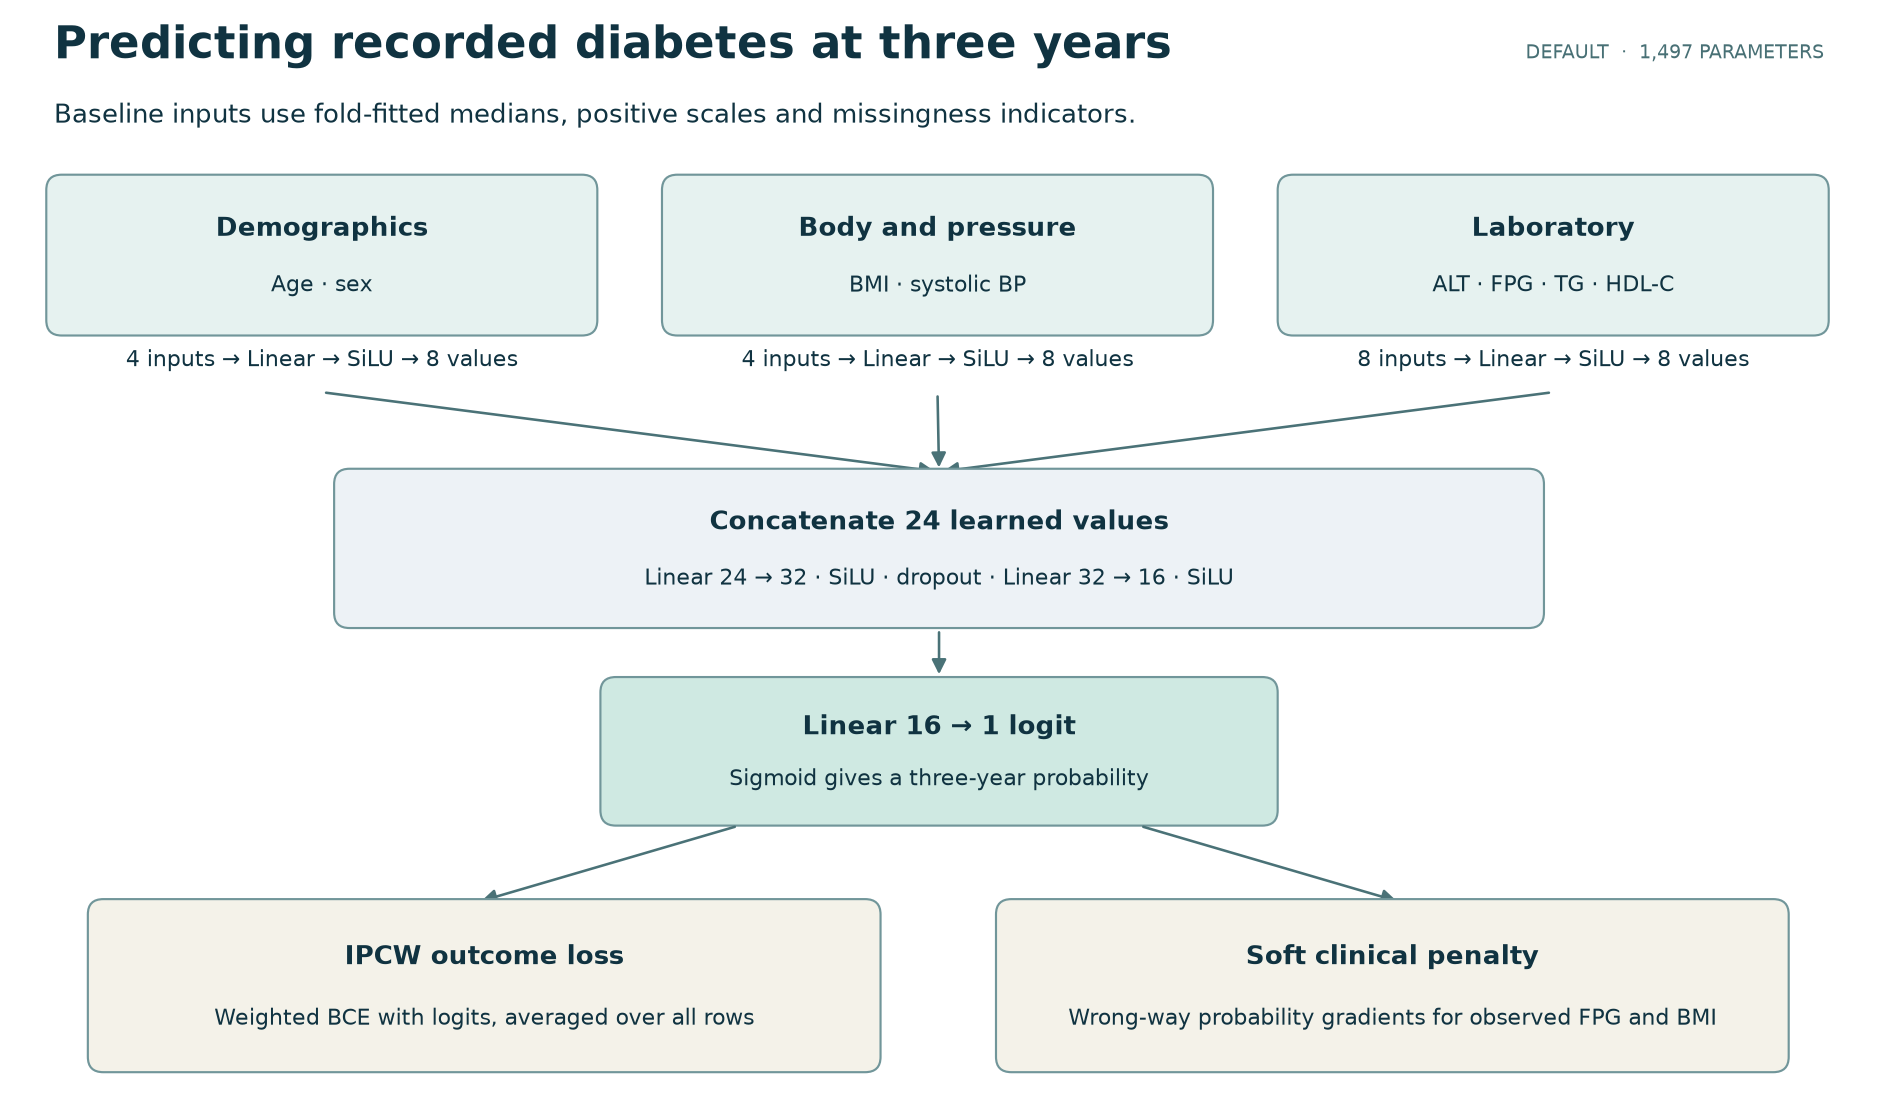

In [ ]:
# 16 · Build the matched networks
if active(16):
    display(Image(filename=str(Path(package) / 'architecture.png')))

## 17 · Differentiate the soft penalty

Penalize the wrong sign of the local probability derivative. Increasing FPG and BMI have positive priors in A. Only observed, in-support pairs contribute. A gradient graph is needed because training differentiates the penalty itself.

**What to look for.** Artificial examples verify parameter-gradient changes at positive lambda, missing-mask exclusion and the HDL direction.

**If the stage stops.** Compare the analytical derivative in raw units with a small central difference if a sign check fails.

In [ ]:
# 17 · Differentiate the soft penalty
if active(17):
    test_cases(['test_loss_denominator_and_penalty', 'test_derivative_sign_masks_and_raw_finite_difference'])
    print(inspect.getsource(clinical))

test_loss_denominator_and_penalty (verify.Checks.test_loss_denominator_and_penalty) ... ok
test_derivative_sign_masks_and_raw_finite_difference (verify.Checks.test_derivative_sign_masks_and_raw_finite_difference) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.136s

OK


def clinical(p,x,inside,names,directions):
    if not directions: return x.new_zeros(())
    idx=[names.index(k) for k in directions]
    signs=x.new_tensor([DIRECTIONS[k] for k in directions])
    g=torch.autograd.grad(p.sum(),x,create_graph=True)[0][:,idx]
    terms=torch.relu(-g*signs).square()
    ok=inside[:,idx]
    return (terms*ok).sum()/ok.sum().clamp_min(1)



## 18 · Define statistical comparators

Fit LR, RF, boosted trees and a linear SVM using IPCW. Calibrate SVM scores on training-only out-of-fold data. Ridge Cox uses administrative truncation at three years and a training baseline hazard. Include a constant reference.

**What to look for.** The active model list and per-comparator candidate budget are printed.

**If the stage stops.** A named dependency or estimator-weight failure must be resolved before interpreting its comparison.

In [ ]:
# 18 · Define statistical comparators
if active(18):
    print(st.cfg['models'], 'Comparator candidate budget', st.b['comparator_trials'])

['M1', 'M3', 'reference', 'LR', 'RF', 'XGB', 'LGB', 'SVM', 'Cox'] Comparator candidate budget 1


## 19 · Tune, stop and checkpoint

Each inner fold learns preprocessing and its own censoring weights. Select by validation Brier, record the stopping epoch, and refit on the outer training partition. Neural checkpoints save optimizer, RNGs and progress at epoch boundaries.

**What to look for.** The budget and private checkpoint directory identify this run.

**If the stage stops.** After interruption, use the identical profile, code and environment and rerun the interrupted stage.

In [ ]:
# 19 · Tune, stop and checkpoint
if active(19):
    print(st.b, 'Resume directory', st.private)

{'outer': 2, 'inner': 2, 'trials': 2, 'epochs': 2, 'patience': 1, 'final_seeds': 1, 'bootstrap': 5, 'comparator_trials': 1, 'sample': 6000} Resume directory /content/drive/MyDrive/CKINN_OBJ1/checkpoints/SMOKE/9952757e3896a2d3


## 20 · Run small software checks

Use artificial data to exercise the split rules, forbidden features, direction penalty, sample-weight response, ZIP safety and exact CPU checkpoint resumption. SMOKE separately uses small real-data samples to exercise the workflow.

**What to look for.** The verification report is written only after the suite succeeds.

**If the stage stops.** Resolve any failed assertion. A passing test supplies software evidence only.

In [ ]:
# 20 · Run small software checks
if active(20):
    js(st.report / 'software_checks.json', run_checks())

test_boundaries_ties_hand_weights (verify.Checks.test_boundaries_ties_hand_weights) ... ok
test_derivative_sign_masks_and_raw_finite_difference (verify.Checks.test_derivative_sign_masks_and_raw_finite_difference) ... ok
test_epoch_resume_identity (verify.Checks.test_epoch_resume_identity) ... ok
test_estimator_weight_response (verify.Checks.test_estimator_weight_response) ... /usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
ok
test_integrity_and_zip (verify.Checks.test_integrity_and_zip) ... ok
test_loss_denominator_and_penalty (verify.Checks.test_loss_denominator_and_penalty) ... ok
test_matched_zero_and_parameter_count (verify.Checks.test_matched_zero_and_par

## 21 · Nested internal validation in RICH

In each outer training fold, tune each comparator in inner folds. Score the held-out outer participants once and save their predictions privately. The scientific profiles use all eligible RICH participants.

**What to look for.** A fold-by-model table and private OOF predictions are saved. Timings and candidate failures enter the logs.

**If the stage stops.** Resume INTERNAL after reconnection. Review the affected model/fold if all its candidates failed.

In [ ]:
# 21 · Nested internal validation in RICH
if active(21):
    display(st.internal().head())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,fold,model,site,status,scoring_seconds,n,events,controls,unknown,G3,...,cal_slope,ece,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr
0,0,M1,mixed,complete,0.003371,3000,11,1483,1506,0.497062,...,-14.427440,0.458869,0.486020,0.0,1.0,NaN,0.994511,0.0,0.0,1.0
1,0,M2,mixed,complete,0.003371,3000,11,1483,1506,0.497062,...,-14.427440,0.458869,0.486020,0.0,1.0,NaN,0.994511,0.0,0.0,1.0
2,0,M3,mixed,complete,0.004896,3000,11,1483,1506,0.497062,...,-14.427440,0.458869,0.486020,0.0,1.0,NaN,0.994511,0.0,0.0,1.0
3,0,M3_siteG_metric,mixed,complete,0.004896,3000,11,1483,1506,0.497062,...,-14.986434,0.458920,0.486020,0.0,1.0,NaN,0.994538,0.0,0.0,1.0
4,0,reference,mixed,complete,0.001428,3000,11,1483,1506,0.497062,...,NaN,0.000202,0.006134,0.0,1.0,NaN,0.994511,0.0,0.0,1.0


## 22 · Summarize internal diagnostics

Read the completed outer-fold table. Differences among folds can reflect case mix and censoring support. Folds share training participants and cannot be used as independent experimental replicates.

**What to look for.** The table contains fold identifiers, model names, case/control counts and held-out metrics.

**If the stage stops.** If it is absent, run INTERNAL using the same profile and options.

In [ ]:
# 22 · Summarize internal diagnostics
if active(22):
    show(st.table / 'A' / 'A_RICH_nested.csv')
    display(internal_summary(st))

,fold,model,site,status,scoring_seconds,n,events,controls,unknown,G3,...,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr,profile,evidence_use
0,0,M1,mixed,complete,0.003371,3000,11,1483,1506,0.497062,...,0.486020,0.000000,1.000000,NaN,0.994511,0.000000,0.000000,1.000000,SMOKE,software check only
1,0,M2,mixed,complete,0.003371,3000,11,1483,1506,0.497062,...,0.486020,0.000000,1.000000,NaN,0.994511,0.000000,0.000000,1.000000,SMOKE,software check only
2,0,M3,mixed,complete,0.004896,3000,11,1483,1506,0.497062,...,0.486020,0.000000,1.000000,NaN,0.994511,0.000000,0.000000,1.000000,SMOKE,software check only
3,0,M3_siteG_metric,mixed,complete,0.004896,3000,11,1483,1506,0.497062,...,0.486020,0.000000,1.000000,NaN,0.994538,0.000000,0.000000,1.000000,SMOKE,software check only
4,0,reference,mixed,complete,0.001428,3000,11,1483,1506,0.497062,...,0.006134,0.000000,1.000000,NaN,0.994511,0.000000,0.000000,1.000000,SMOKE,software check only
5,0,LR,mixed,complete,0.003613,3000,11,1483,1506,0.497062,...,0.013559,0.359982,0.910317,0.021673,0.996135,0.040885,0.089683,0.640018,SMOKE,software check only
6,0,RF,mixed,complete,0.004061,3000,11,1483,1506,0.497062,...,0.015391,0.525838,0.898179,0.027713,0.997095,0.052651,0.101821,0.474162,SMOKE,software check only
7,0,XGB,mixed,complete,0.002586,3000,11,1483,1506,0.497062,...,0.008145,0.267438,0.910991,0.016313,0.995581,0.030750,0.089009,0.732562,SMOKE,software check only
8,0,LGB,mixed,complete,0.003484,3000,11,1483,1506,0.497062,...,0.007742,0.516442,0.899528,0.027587,0.997042,0.052376,0.100472,0.483558,SMOKE,software check only
9,0,SVM,mixed,complete,0.002850,3000,11,1483,1506,0.497062,...,0.012311,0.000000,1.000000,NaN,0.994511,0.000000,0.000000,1.000000,SMOKE,software check only


,model,status,n,events,controls,unknown,G3,at_risk_3,ESS,positive_w_min,...,cal_slope,ece,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr
0,M1,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,-20.136380,0.458796,fold-specific,0.000000,1.000000,NaN,0.994413,0.000000,0.000000,1.000000
1,M2,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,-20.136380,0.458796,fold-specific,0.000000,1.000000,NaN,0.994413,0.000000,0.000000,1.000000
2,M3,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,-20.136380,0.458796,fold-specific,0.000000,1.000000,NaN,0.994413,0.000000,0.000000,1.000000
3,reference,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,-0.986230,0.000200,fold-specific,0.000000,1.000000,NaN,0.994413,0.000000,0.000000,1.000000
4,LR,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,0.388358,0.005118,fold-specific,0.302846,0.899831,0.016704,0.995666,0.031661,0.100169,0.697154
5,RF,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,0.598936,0.002646,fold-specific,0.384499,0.921417,0.026756,0.996261,0.050031,0.078583,0.615501
6,XGB,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,1.393472,0.003851,fold-specific,0.339883,0.892749,0.017495,0.995863,0.033276,0.107251,0.660117
7,LGB,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,0.894031,0.002216,fold-specific,0.409182,0.910287,0.024987,0.996366,0.047098,0.089713,0.590818
8,SVM,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,0.857269,0.002996,fold-specific,0.168262,0.912648,0.010707,0.994905,0.020133,0.087352,0.831738
9,Cox,computed; pooled OOF; evaluation G from RICH,6000,23,2965,3012,0.496943,2965,2985.855913,1.031105,...,8.278079,0.005145,fold-specific,0.158491,0.962901,0.023441,0.995114,0.040842,0.037099,0.841509


## 23 · Choose final configurations in RICH

Repeat the declared inner comparison on all eligible development data. Record the winning configuration, stopping epoch, validation error and source-derived operating threshold.

**What to look for.** One plan per fitted model is saved before any target scoring.

**If the stage stops.** If plans are missing or invalid, inspect the RICH candidate diagnostics and fix that source-stage issue.

In [ ]:
# 23 · Choose final configurations in RICH
if active(23):
    display(pd.DataFrame(st.final_plan('A')).T)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,h,epochs,score,threshold,trial
M1,"{'branch': 8, 'fusion': [32, 16], 'lr': 0.001,...",2,0.216249,0.469344,0
M3,"{'branch': 8, 'fusion': [32, 16], 'lr': 0.001,...",2,0.216249,0.469344,0
reference,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.00556,0.005953,0
LR,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005553,0.013229,0
RF,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005594,0.01372,0
XGB,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005546,0.009201,0
LGB,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005532,0.009523,0
SVM,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005548,0.009075,0
Cox,"{'C': 1, 'ridge': 0.1, 'trees': 12, 'depth': 3...",1,0.005554,0.00639,0
fixed_zero,"{'branch': 8, 'fusion': [32, 16], 'lr': 0.001,...",2,0.216249,0.469344,0


## 24 · Fit and freeze the final models

Fit the selected configurations on RICH. The final ensemble, when configured, uses a fixed equal-weight average across final seeds. All model and preprocessing hashes enter the freeze manifest.

**What to look for.** The path to a complete immutable manifest appears after all final fits finish.

**If the stage stops.** Resume FINAL after interruption. A mismatched hash requires recovering the trusted artifact or a fresh run.

In [ ]:
# 24 · Fit and freeze the final models
if active(24):
    print(st.freeze('A'))

/content/drive/MyDrive/CKINN_OBJ1/checkpoints/SMOKE/9952757e3896a2d3/frozen/A/manifest.json


## 25 · Score frozen models in NAGALA

Load the frozen source-trained pipelines and apply them to the Japanese cohort. All target probabilities, labels and participant keys stay in the private Drive results. Only aggregate performance is exported.

**What to look for.** A distinct external metrics table appears, alongside private predictions and seed-specific summaries.

**If the stage stops.** Complete FINAL first. A mismatch in the model or participant fingerprint blocks scoring.

In [ ]:
# 25 · Score frozen models in NAGALA
if active(25):
    display(st.score('A'))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,scoring_seconds,n,events,controls,unknown,G3,at_risk_3,ESS,positive_w_min,...,cal_slope,ece,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr
0,M1,0.011210,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,-11.846090,0.390905,0.469344,0.000000,1.000000,NaN,0.992260,0.000000,0.000000,1.000000
1,M3,0.011557,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,-11.846090,0.390905,0.469344,0.000000,1.000000,NaN,0.992260,0.000000,0.000000,1.000000
2,reference,0.004346,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,NaN,0.002153,0.005953,0.000000,1.000000,NaN,0.992260,0.000000,0.000000,1.000000
3,LR,0.004450,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,1.663952,0.004746,0.013229,0.685437,0.903679,0.052592,0.997292,0.097688,0.096321,0.314563
4,RF,0.005664,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.968882,0.003113,0.013720,0.566287,0.857042,0.029974,0.996068,0.056934,0.142958,0.433713
5,XGB,0.007161,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,1.619727,0.005750,0.009201,0.607919,0.865011,0.033938,0.996477,0.064286,0.134989,0.392081
6,LGB,0.007294,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,1.426566,0.005360,0.009523,0.433217,0.889384,0.029645,0.995053,0.055492,0.110616,0.566783
7,SVM,0.003652,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,27.131698,0.009870,0.009075,0.000000,1.000000,NaN,0.992260,0.000000,0.000000,1.000000
8,Cox,0.016787,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,20.540272,0.007738,0.006390,0.387037,0.960628,0.071221,0.995047,0.120304,0.039372,0.612963
9,fixed_zero,0.009854,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,-11.846090,0.390905,0.469344,0.000000,1.000000,NaN,0.992260,0.000000,0.000000,1.000000


## 26 · Compare paired external Brier errors

Subtract M1 error from M3 error for the same NAGALA participants. Resample participants in pairs across models and recompute censoring weights for each draw.

**What to look for.** The saved estimate includes interval bounds, successful replicate counts and failures.

**If the stage stops.** A wide or zero-crossing interval is a valid result. Check support when an interval is unavailable.

In [ ]:
# 26 · Compare paired external Brier errors
if active(26):
    display(pd.Series(external_contrast(st)))

,0
comparison,M3 minus M1
task,A
delta,0.0
delta_lo,0.0
delta_hi,0.0
delta_valid_boot,5
requested_boot,5
failed_boot,0


## 27 · Inspect calibration, ranking and thresholds

Plot assigned probability against observed risk, and draw ROC and precision–recall curves. Apply the threshold chosen on RICH validation predictions. Review sensitivity and specificity at that threshold.

**What to look for.** A three-panel plot and calibration-bin table are saved for the external cohort.

**If the stage stops.** If only one class is supported, treat the corresponding rank measure as unavailable.

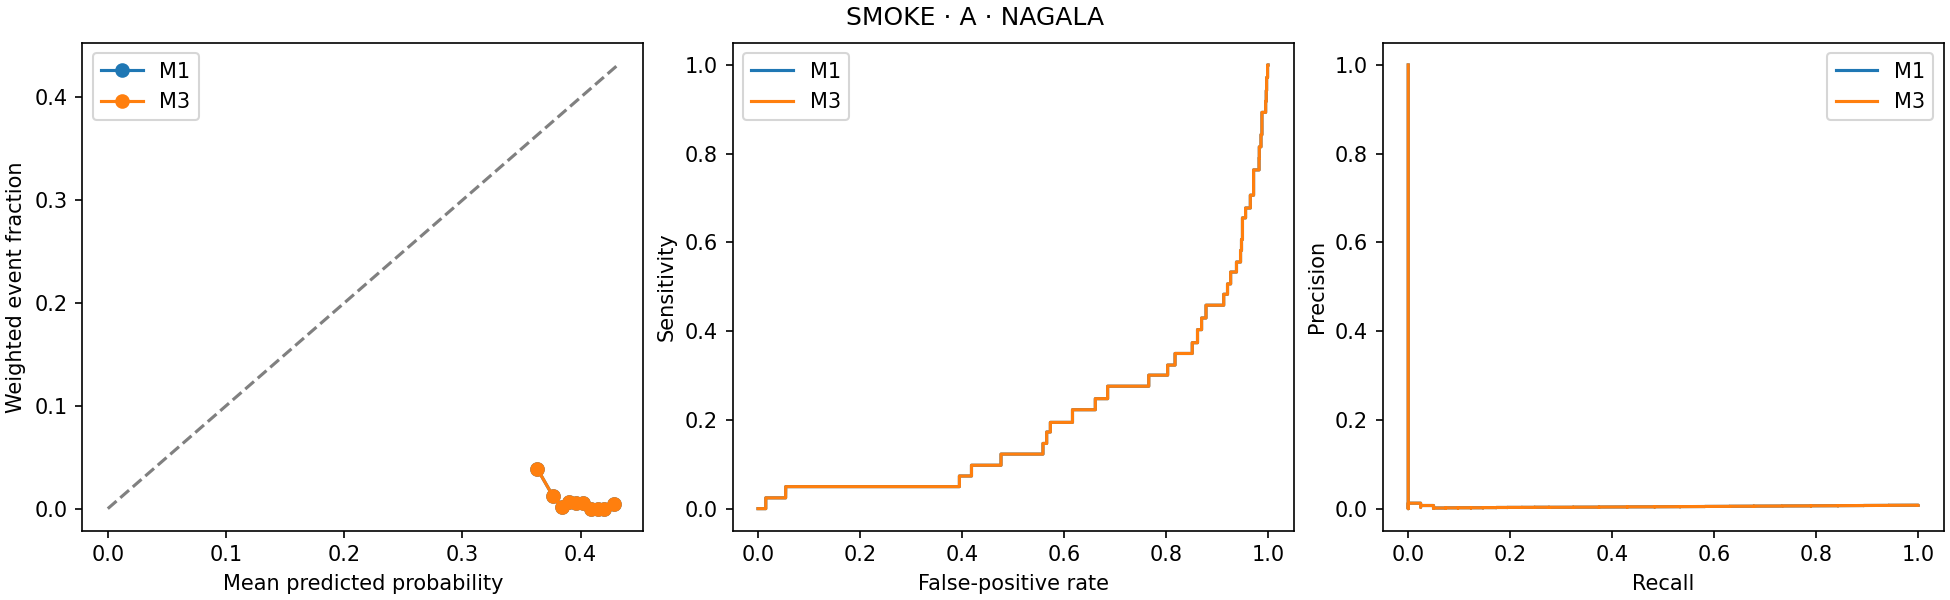

In [ ]:
# 27 · Inspect calibration, ranking and thresholds
if active(27):
    figures(st, 'A')
    show(st.fig / 'A' / 'calibration_roc_pr.png')

## 28 · Compare M1–M5 and single component changes

M2 reuses M1 scores. M4 adds training site weights; M5 adds a sex-specific loss-gap penalty. Independent component contrasts fix epochs and base hyperparameters and change one component at a time.

**What to look for.** The ablation table references the same frozen predictions as the external metrics table.

**If the stage stops.** Enable ablations in 01 before starting the scientific profile. Skipped branches have no result.

In [ ]:
# 28 · Compare M1–M5 and single component changes
if active(28):
    if opt['ablations']:
        p = st.table / 'A' / 'external_metrics.csv'
        if not p.exists():
            raise RuntimeError('Complete FINAL and EXTERNAL before ABLATIONS')
        df = pd.read_csv(p)
        if not set(VARIANTS).issubset(df.model):
            raise ValueError('Component fits missing from frozen manifest')
        csv(st.table / 'A' / 'ablations.csv', df[df.model.isin(VARIANTS + ['M1', 'M2', 'M3'])])
        show(st.table / 'A' / 'ablations.csv')
    else:
        print('Component analyses disabled in this run.')

,model,scoring_seconds,n,events,controls,unknown,G3,at_risk_3,ESS,positive_w_min,...,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr,profile,evidence_use
0,M1,0.011210,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
1,M3,0.011557,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
2,fixed_zero,0.009854,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
3,M4,0.010114,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469536,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
4,M5,0.012729,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469506,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
5,fpg_only,0.008967,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
6,bmi_only,0.011318,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
7,expanded_prior,0.013841,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.469344,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
8,expanded_inputs,0.009625,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.419956,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only
9,no_masks,0.009710,6000,39,4267,1694,0.716714,4267,4304.961462,1.007218,...,0.445480,0.0,1.000000,NaN,0.992260,0.0,0.000000,1.0,SMOKE,software check only


## 29 · Inspect missingness and validation sensitivities

Review eight- versus twelve-feature availability, mask removal, ALT zeros, broader RICH eligibility, site-held-out validation and conditional censoring. Site codes can have too little horizon support.

**What to look for.** Enabled sensitivity runs have distinct table names. The notebook prints each disabled option.

**If the stage stops.** A missing support group stays visible. Enable expensive options in 01 before selecting a run.

In [ ]:
# 29 · Inspect missingness and validation sensitivities
if active(29):
    for option, src, site in [('site_holdout', 'RICH', True), ('broader_rich', 'RICH_broad', False), ('alt_zero', 'RICH_alt0', False)]:
        if opt[option]:
            display(st.internal(source=src, site=site).head())
        else:
            print('Disabled', option)
    print('Site-IPCW sensitivity is fitted in stage 21 when enabled:', opt['site_ipcw'])
    show(st.auditpath / 'feature_set_availability.csv')

Disabled site_holdout
Disabled broader_rich
Disabled alt_zero
Site-IPCW sensitivity is fitted in stage 21 when enabled: True


,cohort,set,features,n,all_observed,at_least_one_missing
0,RICH,nonlaboratory,4,204640,204620,20
1,RICH,primary,8,204640,112070,92570
2,RICH,expanded,12,204640,12168,192472
3,NAGALA,nonlaboratory,4,15459,15459,0
4,NAGALA,primary,8,15459,15448,11
5,NAGALA,expanded,12,15459,15448,11


## 30 · Explain risk and audit clinical direction

Use source training medians for Integrated Gradients, then perturb observed raw FPG or BMI within training support. Compare the ensemble's analytical raw-input gradient and a central difference. Save individual cases privately.

**What to look for.** Direction tables show eligible denominators, violations, magnitudes, near-flat fractions and numerical checks.

**If the stage stops.** Investigate numerical failures before reporting direction consistency. Attributions and derivatives answer different questions.

In [ ]:
# 30 · Explain risk and audit clinical direction
if active(30):
    if opt['explain']:
        explain(st, 'A')
        show(st.table / 'A' / 'directions.csv')
    else:
        print('Explanations disabled.')

,model,deployment,feature,raw_step,n_sample,n_eligible,violations,violation_rate,mean_wrong_way_change,meaningful_fraction,flat_fraction,gradient_violation_rate,max_standardized_check_error,finite_gradient_check,profile,evidence_use
0,M1,frozen_average,bmi,1.0,512,493,8,0.016227,6.508150e-07,0.448276,0.000000,0.008114,0.000007,True,SMOKE,software check only
1,M1,frozen_average,fpg,0.1,512,491,490,0.997963,1.374124e-03,0.763747,0.000000,0.997963,0.000008,True,SMOKE,software check only
2,M3,frozen_average,bmi,1.0,512,493,8,0.016227,6.508150e-07,0.448276,0.000000,0.008114,0.000007,True,SMOKE,software check only
3,M3,frozen_average,fpg,0.1,512,491,490,0.997963,1.374124e-03,0.763747,0.000000,0.997963,0.000008,True,SMOKE,software check only
4,expanded_prior,frozen_average,fpg,0.1,512,491,490,0.997963,1.374124e-03,0.763747,0.000000,0.997963,0.000008,True,SMOKE,software check only
5,expanded_prior,frozen_average,bmi,1.0,512,493,8,0.016227,6.508150e-07,0.448276,0.000000,0.008114,0.000007,True,SMOKE,software check only
6,expanded_prior,frozen_average,age,1.0,512,503,68,0.135189,1.536757e-05,0.000000,0.001988,0.127237,0.000007,True,SMOKE,software check only
7,expanded_prior,frozen_average,sbp,5.0,512,499,499,1.000000,1.617233e-03,0.971944,0.000000,1.000000,0.000009,True,SMOKE,software check only
8,expanded_prior,frozen_average,tg,0.1,512,454,450,0.991189,2.192336e-04,0.000000,0.000000,0.984581,0.000006,True,SMOKE,software check only
9,expanded_prior,frozen_average,hdl,0.1,512,464,464,1.000000,3.231463e-03,1.000000,0.000000,1.000000,0.000008,True,SMOKE,software check only


## 31 · Evaluate prespecified subgroups

Evaluate age, sex, RICH site, lower baseline FPG and availability subgroups. Use the same frozen model in NAGALA and participant-disjoint OOF predictions in RICH. Display groups with sparse evidence.

**What to look for.** Rows include N, known cases, controls and unknowns, plus intervals where there are at least 20 cases and 20 controls.

**If the stage stops.** If a group fails the support rule, report its counts without interpreting its performance.

In [ ]:
# 31 · Evaluate prespecified subgroups
if active(31):
    if opt['subgroups']:
        display(subgroups(st, 'A').head())
    else:
        print('Subgroups disabled.')

,model,stage,group,n,events,controls,unknown,status,G3,at_risk_3,...,ppv_hi,ppv_valid_boot,npv_lo,npv_hi,npv_valid_boot,f1_lo,f1_hi,f1_valid_boot,requested_boot,failed_boot
0,M1,external,all,6000,39,4267,1694,estimated,0.716714,4267.0,...,NaN,0.0,0.989773,0.994621,5.0,0.0,0.0,5.0,5.0,0.0
1,M1,external,sex_code_0,2699,7,1910,782,insufficient known cases or controls,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,M1,external,sex_code_1,3301,32,2357,912,estimated,0.722388,2357.0,...,NaN,0.0,0.985395,0.988106,5.0,0.0,0.0,5.0,5.0,0.0
3,M1,external,age_20_39,2140,5,1503,632,insufficient known cases or controls,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,M1,external,age_40_59,3559,27,2581,951,estimated,0.731756,2581.0,...,NaN,0.0,0.989467,0.992824,5.0,0.0,0.0,5.0,5.0,0.0


## 32 · Optional target intercept update

Reserve target participants for updating and disjoint participants for evaluation. Compare the original and intercept-updated predictions on the same evaluation people after reporting the primary frozen results.

**What to look for.** If enabled, a table records support, estimated offset and same-subset results, or an explicit skip reason.

**If the stage stops.** If the reserved participants contain too few outcomes, retain the recorded skip.

In [ ]:
# 32 · Optional target intercept update
if active(32):
    if opt['target_update']:
        display(pd.DataFrame(updating(st)))
    else:
        print('Target updating disabled.')

Target updating disabled.


## 33 · Audit independent NHANES screening eligibility

Select adults with measured HbA1c and the extract's binary no-diagnosis code. Flag a screen at HbA1c ≥6.5%. Primary eligibility depends on verified DIQ010 recoding. Default output is labelled as-coded.

**What to look for.** The stage displays both periods, candidate counts and the evidence status of the binary recode.

**If the stage stops.** Only switch to verified eligibility after obtaining the producer crosswalk. Keep coded sex labels until its mapping is established.

In [ ]:
# 33 · Audit independent NHANES screening eligibility
if active(33):
    show(st.auditpath / 'cohort_flow.csv')
    print('NHANES analysis label', st.tag('B'), 'Producer recode evidence:', opt['producer_recode_evidence'] or 'unavailable')

,cohort,step,n,events,cases3,status
0,RICH,raw,211833,4174,1764.0,NaN
1,RICH,age >=20,211833,4174,1764.0,NaN
2,RICH,positive finite follow-up,211833,4174,1764.0,NaN
3,RICH,binary event,211833,4174,1764.0,NaN
4,RICH,observed FPG <7 and source baseline exclusions,211833,4174,1764.0,NaN
5,RICH,harmonized FPG <6.1,204640,2238,785.0,NaN
6,RICH_broad,raw,211833,4174,1764.0,NaN
7,RICH_broad,age >=20,211833,4174,1764.0,NaN
8,RICH_broad,positive finite follow-up,211833,4174,1764.0,NaN
9,RICH_broad,binary event,211833,4174,1764.0,NaN


NHANES analysis label B_as_coded Producer recode evidence: unavailable


## 34 · Train and freeze the earlier screening period

Develop independently in the 2017–2020 extract. Use Age, Sex, BMI and SBP, and a BMI-only positive prior. Neither glycaemic measurements nor self-reported diabetes can enter model inputs.

**What to look for.** A screening-specific source freeze is saved, separate from the incident-risk model.

**If the stage stops.** Select SCREEN to resume. A missing crosswalk blocks only the verified screening analysis.

In [ ]:
# 34 · Train and freeze the earlier screening period
if active(34):
    if opt['screening'] == 'off':
        print('Screening disabled.')
    else:
        print(st.freeze('B'))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/content/drive/MyDrive/CKINN_OBJ1/checkpoints/SMOKE/9952757e3896a2d3/frozen/B_as_coded/manifest.json


## 35 · Evaluate the later screening period

Apply the frozen screening pipelines in 2021–2023. Report ordinary screening metrics, conditional extract-level uncertainty, subgroup support, and the independent BMI direction audit.

**What to look for.** The B directory contains temporal metrics, curves and selected diagnostics. B has no survey weights.

**If the stage stops.** Inspect temporal drift in measurement and coding. Population-representative inference needs keyed survey design variables.

In [ ]:
# 35 · Evaluate the later screening period
if active(35):
    if opt['screening'] == 'off':
        print('Screening disabled.')
    else:
        display(st.score('B'))
        external_contrast(st, 'B')
        figures(st, 'B')
        if opt['subgroups']:
            subgroups(st, 'B')
        if opt['explain']:
            explain(st, 'B')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,scoring_seconds,n,events,controls,unknown,G3,at_risk_3,ESS,positive_w_min,...,cal_slope,ece,threshold,sensitivity,specificity,ppv,npv,f1,fpr,fnr
0,M1,0.006696,4851,145,4706,0,NaN,None,4851.0,1.0,...,8.855693,0.299588,0.441486,0.000000,1.000000,NaN,0.970109,0.000000,0.000000,1.000000
1,M3,0.006756,4851,145,4706,0,NaN,None,4851.0,1.0,...,8.855693,0.299588,0.441486,0.000000,1.000000,NaN,0.970109,0.000000,0.000000,1.000000
2,reference,0.002809,4851,145,4706,0,NaN,None,4851.0,1.0,...,NaN,0.011109,0.041000,0.000000,1.000000,NaN,0.970109,0.000000,0.000000,1.000000
3,LR,0.003367,4851,145,4706,0,NaN,None,4851.0,1.0,...,1.087080,0.013061,0.081389,0.296552,0.902040,0.085317,0.976536,0.132512,0.097960,0.703448
4,RF,0.007577,4851,145,4706,0,NaN,None,4851.0,1.0,...,2.098627,0.014687,0.073481,0.179310,0.949214,0.098113,0.974051,0.126829,0.050786,0.820690
5,XGB,0.006822,4851,145,4706,0,NaN,None,4851.0,1.0,...,2.699569,0.015530,0.070127,0.075862,0.966851,0.065868,0.971392,0.070513,0.033149,0.924138
6,LGB,0.005806,4851,145,4706,0,NaN,None,4851.0,1.0,...,2.627844,0.016347,0.069799,0.041379,0.987038,0.089552,0.970945,0.056604,0.012962,0.958621
7,SVM,0.003965,4851,145,4706,0,NaN,None,4851.0,1.0,...,1.191737,0.011376,0.072610,0.303448,0.899065,0.084778,0.976685,0.132530,0.100935,0.696552
8,M2,0.006696,4851,145,4706,0,NaN,None,4851.0,1.0,...,8.855693,0.299588,0.441486,0.000000,1.000000,NaN,0.970109,0.000000,0.000000,1.000000


## 36 · Collect publication tables and figures

Read available aggregate tables and summarize actual fit budgets and observed run times. Preserve failed attempts and optional-analysis status when preparing a manuscript.

**What to look for.** The cell lists completed tables and saves the fit budget table when fitting was executed.

**If the stage stops.** If an expected artifact is missing, inspect its prerequisite stage and the run options.

In [ ]:
# 36 · Collect publication tables and figures
if active(36):
    for p in sorted(st.table.rglob('*.csv')):
        print(p.relative_to(st.table))
    if (st.log / 'fits.jsonl').exists():
        fits = pd.read_json(st.log / 'fits.jsonl', lines=True)
        csv(st.table / 'fit_budget.csv', fits.groupby(['task', 'model', 'status'], dropna=False).agg(fits=('model', 'size'), seconds=('seconds', 'sum')).reset_index())

A/A_RICH_nested.csv
A/ablations.csv
A/attributions.csv
A/calibration_bins.csv
A/directions.csv
A/external_metrics.csv
A/ipcw_support.csv
A/paired_brier.csv
A/perturbation.csv
A/pooled_oof.csv
A/seed_metrics.csv
A/sex_gaps.csv
A/subgroups.csv
B_as_coded/attributions.csv
B_as_coded/calibration_bins.csv
B_as_coded/directions.csv
B_as_coded/external_metrics.csv
B_as_coded/paired_brier.csv
B_as_coded/perturbation.csv
B_as_coded/seed_metrics.csv
B_as_coded/sex_gaps.csv
B_as_coded/subgroups.csv


## 37 · Generate a narrative from computed values

Read saved differences and intervals and generate a constrained results narrative. Null, unfavorable and unavailable results are handled explicitly.

**What to look for.** A summary and claim-to-evidence table appear in this run's reports directory.

**If the stage stops.** Never fill an absent result with a proposal example or a result from another profile.

In [ ]:
# 37 · Generate a narrative from computed values
if active(37):
    evidence(st)
    show(st.report / 'summary.md')

# Objective 1 · SMOKE

Reanalysis. Results below are read from this run's saved tables.

Software and data checks only. These outputs support no study performance conclusion.

## A

M3 minus M1 Brier difference 0. The paired 95% interval [0, 0] includes zero. Negative values favor M3. Uncertainty is conditional on these fitted models.

M1 had Brier 0.16045, AUROC 0.1968, average precision 0.004867, mean prediction 0.3983, and adjusted observed fraction 0.00774. Calibration intercept -4.441 and slope -11.85 use 6000 participants with 39 known cases.

M3 had Brier 0.16045, AUROC 0.1968, average precision 0.004867, mean prediction 0.3983, and adjusted observed fraction 0.00774. Calibration intercept -4.441 and slope -11.85 use 6000 participants with 39 known cases.

Analytical versus numerical direction checks recorded 0 disagreements outside tolerance. See eligible denominators and flatness in directions.csv.

120 of 140 model-by-group estimates lacked the prespecified support.

The bina

## 38 · Record the reproducibility manifest

Capture input and code identities, environment, run settings, budgets, available artifacts and frozen hashes. Keep scientific endpoints and software checks distinct.

**What to look for.** The manifest is written alongside the report.

**If the stage stops.** Compare fingerprints if two sessions give different results or seem to reuse the wrong cache.

In [ ]:
# 38 · Record the reproducibility manifest
if active(38):
    evidence(st)
    show(st.report / 'run_manifest.json')

{
  "mode": "SMOKE",
  "run": "9952757e3896a2d3",
  "identity": {
    "data": {
      "proposal": "fc5f4d618ba1bb0d33d8d44f541846e75699268a24e1c851fbee275c00307b10",
      "NHANES": "3af63d0d53d8f88c38a7f54d80e6e448014322f7c8c3fe115ba9b3e47c2c6acf",
      "NAGALA": "671359aea2019c848f969395f88e57f888eaba8463ea0351bcda8f1c947f5523",
      "RICH": "ffd341a1a91ac65585b9fba70847a2681f5671a6035d9cfbf92e50795d74fbf6"
    },
    "code": "772ad6e9fa6d8efca6679af15a33bbcc48b12afbe3984a9baeb2afaee6e0432a",
    "config": "5a40dc396c2a64a82db1a2a8a42b8d17bd07eb62ff14a381f901a2cc0df318c8",
    "device": "cpu",
    "runtime": {
      "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
      "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
      "cuda": null,
      "device_name": "CPU"
    },
    "versions": {
      "numpy": "2.4.6",
      "pandas": "2.2.3",
      "scipy": "1.16.3",
      "scikit-learn": "1.6.1",
      "torch": "2.14.1+cpu",
      "lifelines": "0.30.3",
      "lightgbm

## 39 · Export aggregates and resume later

Create a ZIP of aggregate tables and figures, code and reproducibility metadata. Models, row-level probabilities, individual explanations and source data stay in the private Drive directories.

**What to look for.** The output path identifies this profile's aggregate ZIP. Download it from Drive when needed.

**If the stage stops.** To resume, select the same mode and settings in 01 and a specific RUN_STAGE; run setup and the selected stage.

In [ ]:
# 39 · Export aggregates and resume later
if active(39):
    print(export(st, package))

/content/drive/MyDrive/CKINN_OBJ1/results/reports/SMOKE/9952757e3896a2d3/CKINN_SMOKE_aggregate.zip
